Import required libraries

In [ ]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Machine learning models
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Model evaluation
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

# Display settings
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
import pandas as pd

df = pd.read_csv('/content/StudentsPerformance.csv')

# Display first five rows
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


Inspect the dataset
Head , shape , info , describe , Is null , duplicate

In [ ]:
# Display first five records
display(df.head())

# Dataset dimensions
print("Dataset Shape:", df.shape)

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Dataset information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe(include='all'))

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


Dataset Shape: (1000, 8)

Column Names:
['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB

Statistical Summary:


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
count,1000,1000,1000,1000,1000,1000.00000,1000.000000,1000.000000
unique,2,5,6,2,2,NaN,NaN,NaN
top,female,group C,some college,standard,none,NaN,NaN,NaN
freq,518,319,226,645,642,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,66.08900,69.169000,68.054000
std,NaN,NaN,NaN,NaN,NaN,15.16308,14.600192,15.195657
min,NaN,NaN,NaN,NaN,NaN,0.00000,17.000000,10.000000
25%,NaN,NaN,NaN,NaN,NaN,57.00000,59.000000,57.750000
50%,NaN,NaN,NaN,NaN,NaN,66.00000,70.000000,69.000000
75%,NaN,NaN,NaN,NaN,NaN,77.00000,79.000000,79.000000



Missing Values:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

Duplicate Records: 0


Clean column names and duplicate records

In [ ]:
# Create a copy of the original dataset
df = df.copy()

# Clean column names
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(r'[^a-z0-9]+', '_', regex=True)
    .str.strip('_')
)

# Remove duplicate records
df.drop_duplicates(inplace=True)

# Check missing values
print("Missing values after cleaning:")
print(df.isnull().sum())

# Check duplicates again
print("\nDuplicates after cleaning:", df.duplicated().sum())

# Display cleaned dataset
display(df.head())

print("\nDataset cleaned successfully!")

Missing values after cleaning:
gender                         0
race_ethnicity                 0
parental_level_of_education    0
lunch                          0
test_preparation_course        0
math_score                     0
reading_score                  0
writing_score                  0
dtype: int64

Duplicates after cleaning: 0


,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75



Dataset cleaned successfully!


Check invalid values

In [ ]:
score_columns = [
    'math_score',
    'reading_score',
    'writing_score'
]

for col in score_columns:
    print(f"\n{col}")
    print("Minimum:", df[col].min())
    print("Maximum:", df[col].max())

# Check invalid scores
for col in score_columns:
    invalid = df[(df[col] < 0) | (df[col] > 100)]
    print(f"Invalid values in {col}: {len(invalid)}")


math_score
Minimum: 0
Maximum: 100

reading_score
Minimum: 17
Maximum: 100

writing_score
Minimum: 10
Maximum: 100
Invalid values in math_score: 0
Invalid values in reading_score: 0
Invalid values in writing_score: 0


Overall student score analysis

In [ ]:
# Calculate average scores
print("Average Math Score:", df['math_score'].mean())
print("Average Reading Score:", df['reading_score'].mean())
print("Average Writing Score:", df['writing_score'].mean())

# Calculate total average score
df['average_score'] = df[
    ['math_score', 'reading_score', 'writing_score']
].mean(axis=1)

display(df.head())

Average Math Score: 66.089
Average Reading Score: 69.169
Average Writing Score: 68.054


,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,average_score
0,female,group B,bachelor's degree,standard,none,72,72,74,72.666667
1,female,group C,some college,standard,completed,69,90,88,82.333333
2,female,group B,master's degree,standard,none,90,95,93,92.666667
3,male,group A,associate's degree,free/reduced,none,47,57,44,49.333333
4,male,group C,some college,standard,none,76,78,75,76.333333


Analyze categorical variables

In [ ]:
categorical_columns = [
    'gender',
    'race_ethnicity',
    'parental_level_of_education',
    'lunch',
    'test_preparation_course'
]

for col in categorical_columns:
    print(f"\nDistribution of {col}:")
    print(df[col].value_counts())


Distribution of gender:
gender
female    518
male      482
Name: count, dtype: int64

Distribution of race_ethnicity:
race_ethnicity
group C    319
group D    262
group B    190
group E    140
group A     89
Name: count, dtype: int64

Distribution of parental_level_of_education:
parental_level_of_education
some college          226
associate's degree    222
high school           196
some high school      179
bachelor's degree     118
master's degree        59
Name: count, dtype: int64

Distribution of lunch:
lunch
standard        645
free/reduced    355
Name: count, dtype: int64

Distribution of test_preparation_course:
test_preparation_course
none         642
completed    358
Name: count, dtype: int64


Correlation analysis

               math_score  reading_score  writing_score
math_score       1.000000       0.817580       0.802642
reading_score    0.817580       1.000000       0.954598
writing_score    0.802642       0.954598       1.000000


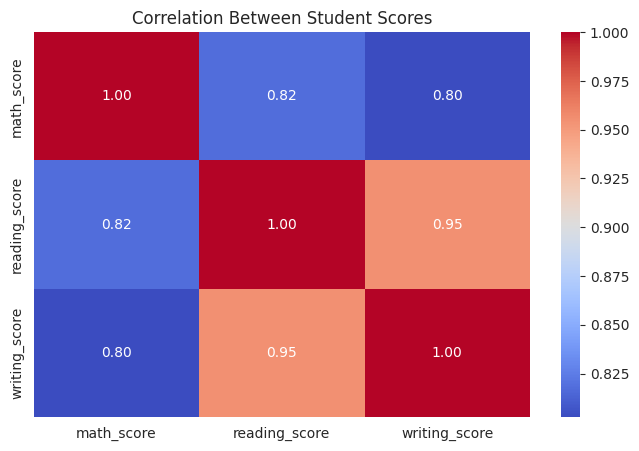

In [ ]:
correlation = df[score_columns].corr()

print(correlation)

plt.figure(figsize=(8, 5))
sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Between Student Scores")
plt.show()

**Data visualization**

Score distributions

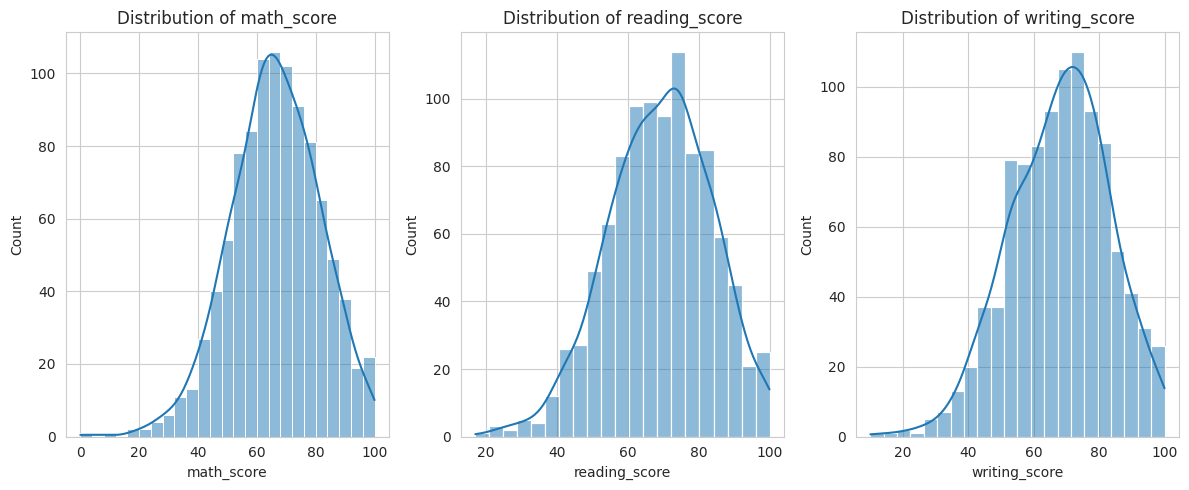

In [ ]:
plt.figure(figsize=(12, 5))

for i, col in enumerate(score_columns, 1):
    plt.subplot(1, 3, i)
    sns.histplot(df[col], kde=True)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)

plt.tight_layout()
plt.show()

Gender versus scores

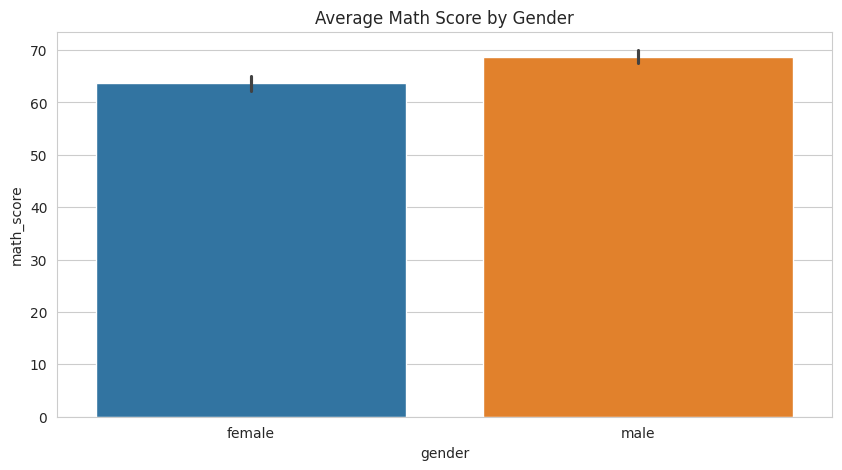

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x='gender',
    y='math_score',
    hue='gender'
)

plt.title("Average Math Score by Gender")
plt.show()

Test preparation versus performance

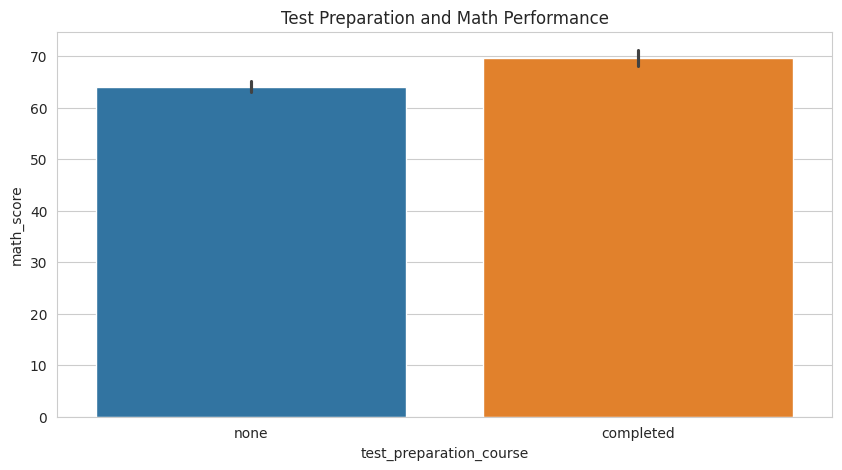

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x='test_preparation_course',
    y='math_score',
    hue='test_preparation_course'
)

plt.title("Test Preparation and Math Performance")
plt.show()

Boxplots for score comparison

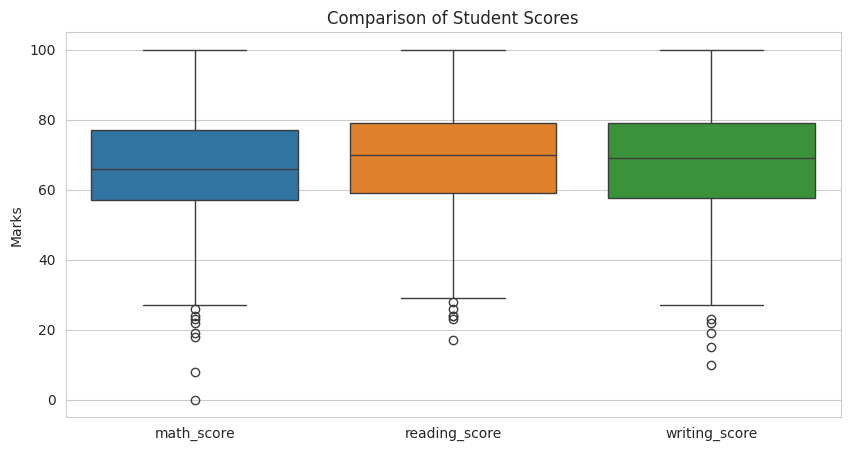

In [ ]:
plt.figure(figsize=(10, 5))

sns.boxplot(data=df[score_columns])

plt.title("Comparison of Student Scores")
plt.ylabel("Marks")
plt.show()

Parental education versus student scores

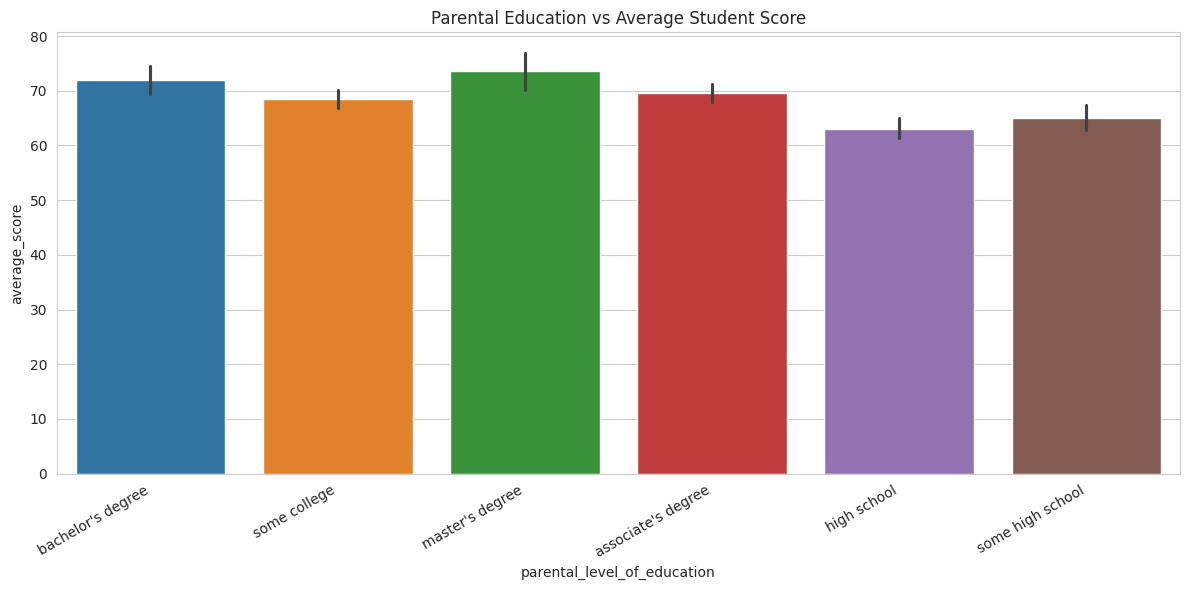

In [ ]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=df,
    x='parental_level_of_education',
    y='average_score',
    hue='parental_level_of_education'
)

plt.xticks(rotation=30, ha='right')
plt.title("Parental Education vs Average Student Score")
plt.tight_layout()
plt.show()

Feature selection

In [ ]:
# Independent variables
X = df.drop(columns=['math_score', 'average_score'])

# Dependent variable
y = df['math_score']

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

print("\nX Shape:", X.shape)
print("y Shape:", y.shape)

Features:
['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course', 'reading_score', 'writing_score']

Target:
math_score

X Shape: (1000, 7)
y Shape: (1000,)


Train-test split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (800, 7)
Testing Features: (200, 7)
Training Target: (800,)
Testing Target: (200,)


Preprocessing pipeline

In [ ]:
# Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

print("Numerical Features:", numeric_features)
print("Categorical Features:", categorical_features)

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Numerical Features: ['reading_score', 'writing_score']
Categorical Features: ['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course']
Preprocessing pipeline created successfully!


**Machine learning model training**

Create and train models

In [ ]:
models = {
    'Linear Regression': LinearRegression(),

    'Random Forest': RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ),

    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42
    )
}

trained_models = {}
results = []

for name, model in models.items():

    # Create complete pipeline
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    # Train model
    pipeline.fit(X_train, y_train)

    # Predict test data
    y_pred = pipeline.predict(X_test)

    # Evaluate model
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    # Save trained model
    trained_models[name] = pipeline

    results.append({
        'Model': name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    })

print("All models trained successfully!")

All models trained successfully!


**Compare model performance**

In [ ]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='R2 Score',
    ascending=False
)

display(results_df)

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,4.214763,29.095170,5.393994,0.880433
2,Gradient Boosting,4.303784,31.097058,5.576474,0.872207
1,Random Forest,4.633300,35.630632,5.969140,0.853576


Visualize model comparison

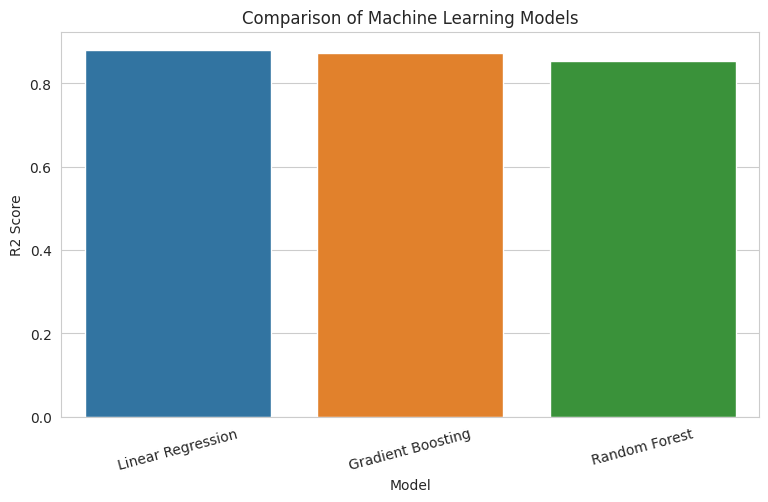

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x='Model',
    y='R2 Score',
    hue='Model'
)

plt.title("Comparison of Machine Learning Models")
plt.ylabel("R2 Score")
plt.xticks(rotation=15)
plt.show()

Select the best model

In [ ]:
best_model_name = results_df.iloc[0]['Model']

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)
print("Best R2 Score:", results_df.iloc[0]['R2 Score'])

Best Model: Linear Regression
Best R2 Score: 0.8804332983749565


**Actual vs predicted visualization**

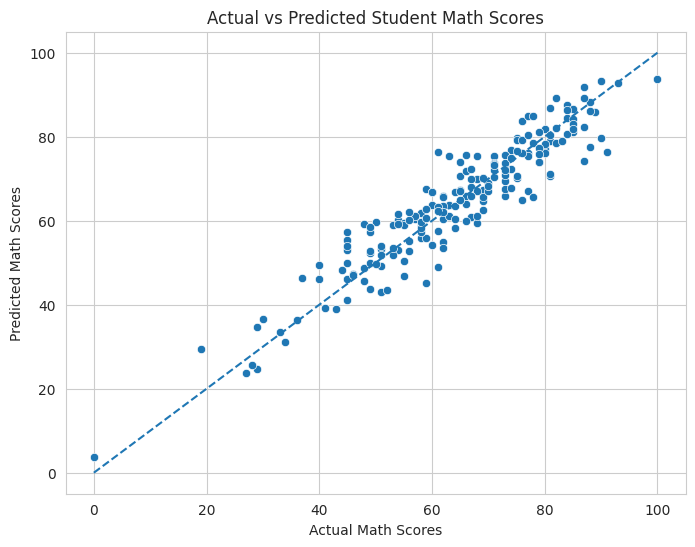

In [ ]:
y_pred_best = best_model.predict(X_test)

plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=y_pred_best
)

plt.plot(
    [0, 100],
    [0, 100],
    linestyle='--'
)

plt.xlabel("Actual Math Scores")
plt.ylabel("Predicted Math Scores")
plt.title("Actual vs Predicted Student Math Scores")

plt.show()

Feature importance

,Feature,Importance
0,num__reading_score,0.555965
1,num__writing_score,0.237070
2,cat__gender_female,0.060647
3,cat__gender_male,0.059772
8,cat__race_ethnicity_group E,0.010319
16,cat__lunch_standard,0.008492
15,cat__lunch_free/reduced,0.007217
13,cat__parental_level_of_education_some college,0.006658
9,cat__parental_level_of_education_associate's d...,0.006605
6,cat__race_ethnicity_group C,0.006339


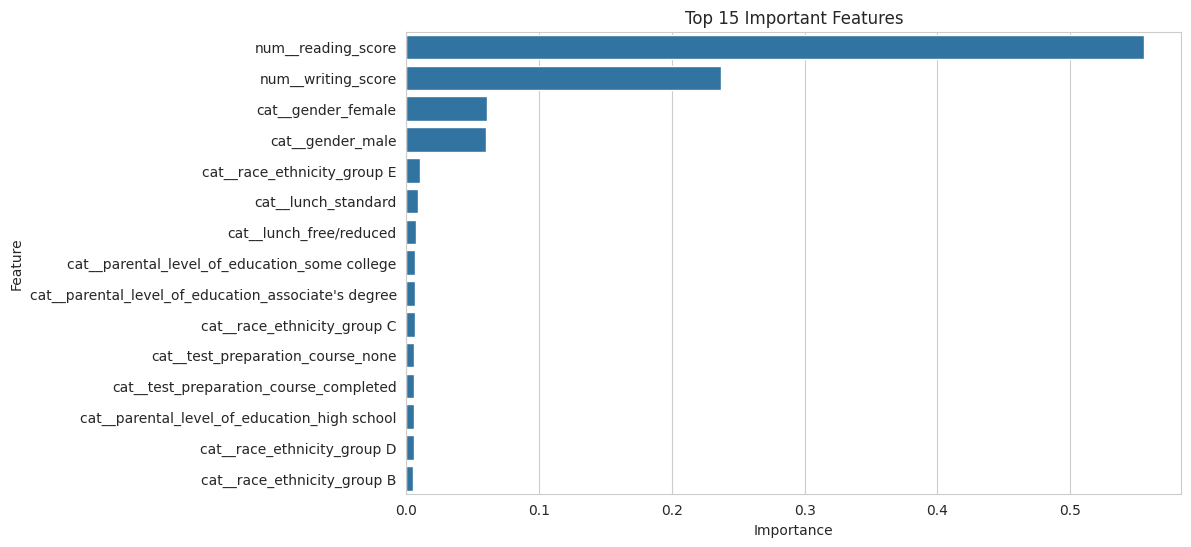

In [ ]:
rf_model = trained_models['Random Forest']

# Get feature names after preprocessing
feature_names = rf_model.named_steps[
    'preprocessor'
].get_feature_names_out()

# Get feature importance
importance = rf_model.named_steps[
    'model'
].feature_importances_

# Create dataframe
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

display(feature_importance.head(15))

# Visualize
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(15),
    x='Importance',
    y='Feature'
)

plt.title("Top 15 Important Features")
plt.show()

**Make predictions**

Predict using testing data

In [ ]:
prediction_results = pd.DataFrame({
    'Actual Math Score': y_test.values,
    'Predicted Math Score': y_pred_best.round(2)
})

display(prediction_results.head(10))

,Actual Math Score,Predicted Math Score
0,91,76.39
1,53,58.89
2,80,76.99
3,74,76.85
4,84,87.63
5,81,79.01
6,69,64.65
7,54,53.01
8,87,74.18
9,51,49.21


Predict for a new student

In [ ]:
new_student = pd.DataFrame({
    'gender': ['female'],
    'race_ethnicity': ['group C'],
    'parental_level_of_education': ['some college'],
    'lunch': ['standard'],
    'test_preparation_course': ['completed'],
    'reading_score': [75],
    'writing_score': [78]
})

# Make prediction
predicted_score = best_model.predict(new_student)

print("Predicted Math Score:", round(predicted_score[0], 2))

Predicted Math Score: 67.16
